In [152]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [153]:
import numpy as np
import matplotlib.pyplot as plt
import sys
sys.path.insert(0, r"c:\users\arthu\documents\swittz-epfl\phd\code\lib\site-packages")
sys.path.append('../')
from pygraphon.graphons import StepGraphon
from pygraphon.estimators import SmoothNetHist

from experiments.utils_generators import AssociativeFullyRandom
from pygraphon.norm import MseProbaEdge, MaeProbaEdge, AUCEdge, AUPRCEdge
from pygraphon.plots.plot_matrices import spy


In [154]:
from palettable.colorbrewer.sequential import YlOrRd_9
# To get the colors as a list of RGB tuples:
colors = YlOrRd_9.mpl_colors
hex_colors = YlOrRd_9.hex_colors
import matplotlib.cm as cm
import matplotlib.colors as colors
cmap = cm.get_cmap('YlOrRd')


# Common graphons

In [155]:
from pygraphon.graphons import common_graphons
n = 40
estimators = {g: {"SSM": None, "Olhede": None} for _,g in enumerate(common_graphons.values())}
for j,g in enumerate(common_graphons.values()):
    adj_mat = g.draw(n=n, exchangeable=False)
    est = SmoothNetHist()
    est.fit(adj_mat)
    estimators[g]["SSM"] = est.graphon
    estimators[g]["Olhede"] = est._first_approximate_graphon_from_adjacency(adj_mat)


In [156]:
from pygraphon.graphons import common_graphons
common_graphons

{'product': <pygraphon.graphons.Graphon.Graphon at 0x1b3e71253a0>,
 'exp_07': <pygraphon.graphons.Graphon.Graphon at 0x1b38728cdc0>,
 'polynomial': <pygraphon.graphons.Graphon.Graphon at 0x1b387299340>,
 'mean': <pygraphon.graphons.Graphon.Graphon at 0x1b3872993d0>,
 'logit_sum': <pygraphon.graphons.Graphon.Graphon at 0x1b387299520>,
 'latent_distance': <pygraphon.graphons.Graphon.Graphon at 0x1b3872995e0>,
 'logit_max_power': <pygraphon.graphons.Graphon.Graphon at 0x1b387299670>,
 'exp_max_power': <pygraphon.graphons.Graphon.Graphon at 0x1b387299700>,
 'exp_polynomial': <pygraphon.graphons.Graphon.Graphon at 0x1b387299790>,
 'log_1_p': <pygraphon.graphons.Graphon.Graphon at 0x1b387299820>,
 'sinusoidal': <pygraphon.graphons.Graphon.Graphon at 0x1b3872998b0>,
 'assortative_sbm': <pygraphon.graphons.StepGraphon.StepGraphon at 0x1b3872999a0>,
 'dissassortative_sbm': <pygraphon.graphons.StepGraphon.StepGraphon at 0x1b387299940>,
 'hsbm': <pygraphon.graphons.StepGraphon.StepGraphon at 0x1b

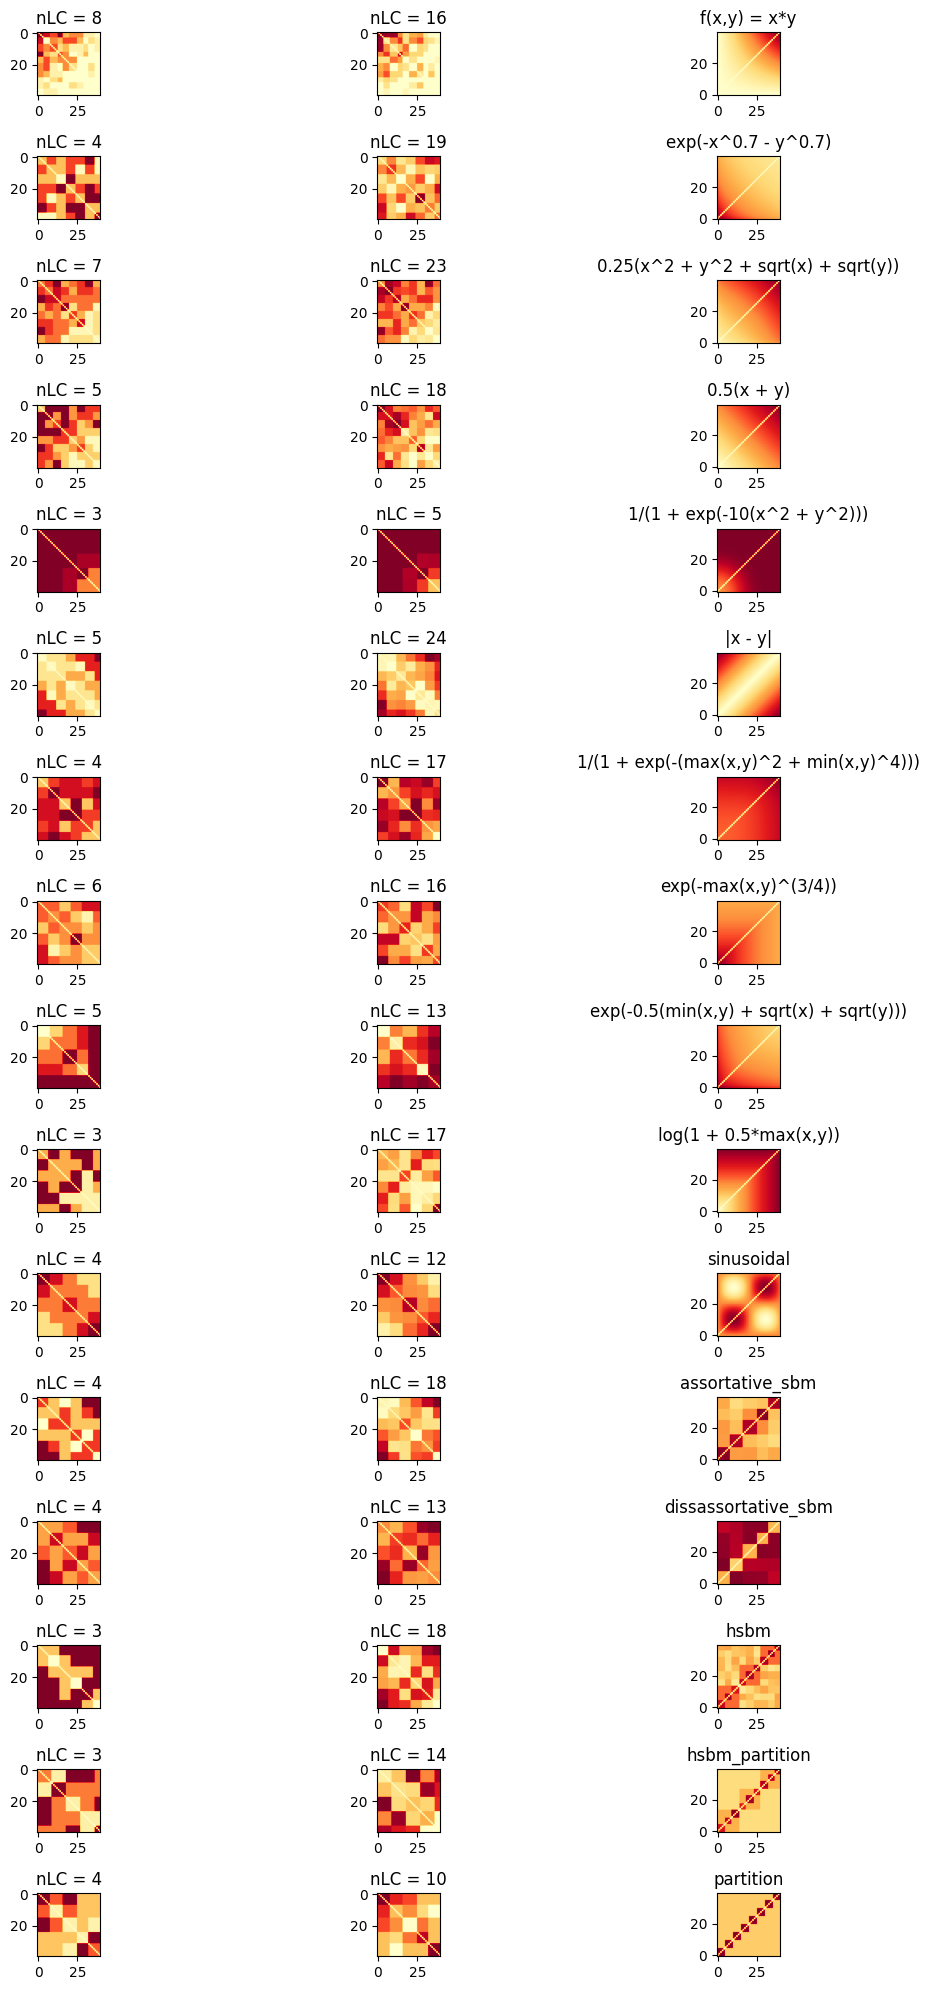

In [157]:
#Plot each graphn and its estimate in subplots iteratively
fig, axes = plt.subplots(nrows=len(common_graphons.values()), ncols=3, figsize=(12, 20))
for j,g in enumerate(common_graphons.values()):
    axes[j,0].imshow(estimators[g]["SSM"].get_edge_probabilities(n,False,True)/estimators[g]["SSM"].initial_rho, cmap = cmap)
    axes[j,0].set_title("nLC = " + str(len(np.unique(estimators[g]["SSM"].graphon))))
    axes[j,1].imshow(estimators[g]["Olhede"][0].get_edge_probabilities(n,False,True)/estimators[g]["Olhede"][0].initial_rho, cmap = cmap)
    axes[j,1].set_title("nLC = " + str(len(np.unique(estimators[g]["Olhede"][0].graphon))))
    axes[j,2].imshow(g.get_edge_probabilities(n,False,True)/g.initial_rho, cmap = cmap, origin='lower')
    axes[j,2].set_title(str(g))
plt.tight_layout()
plt.show()

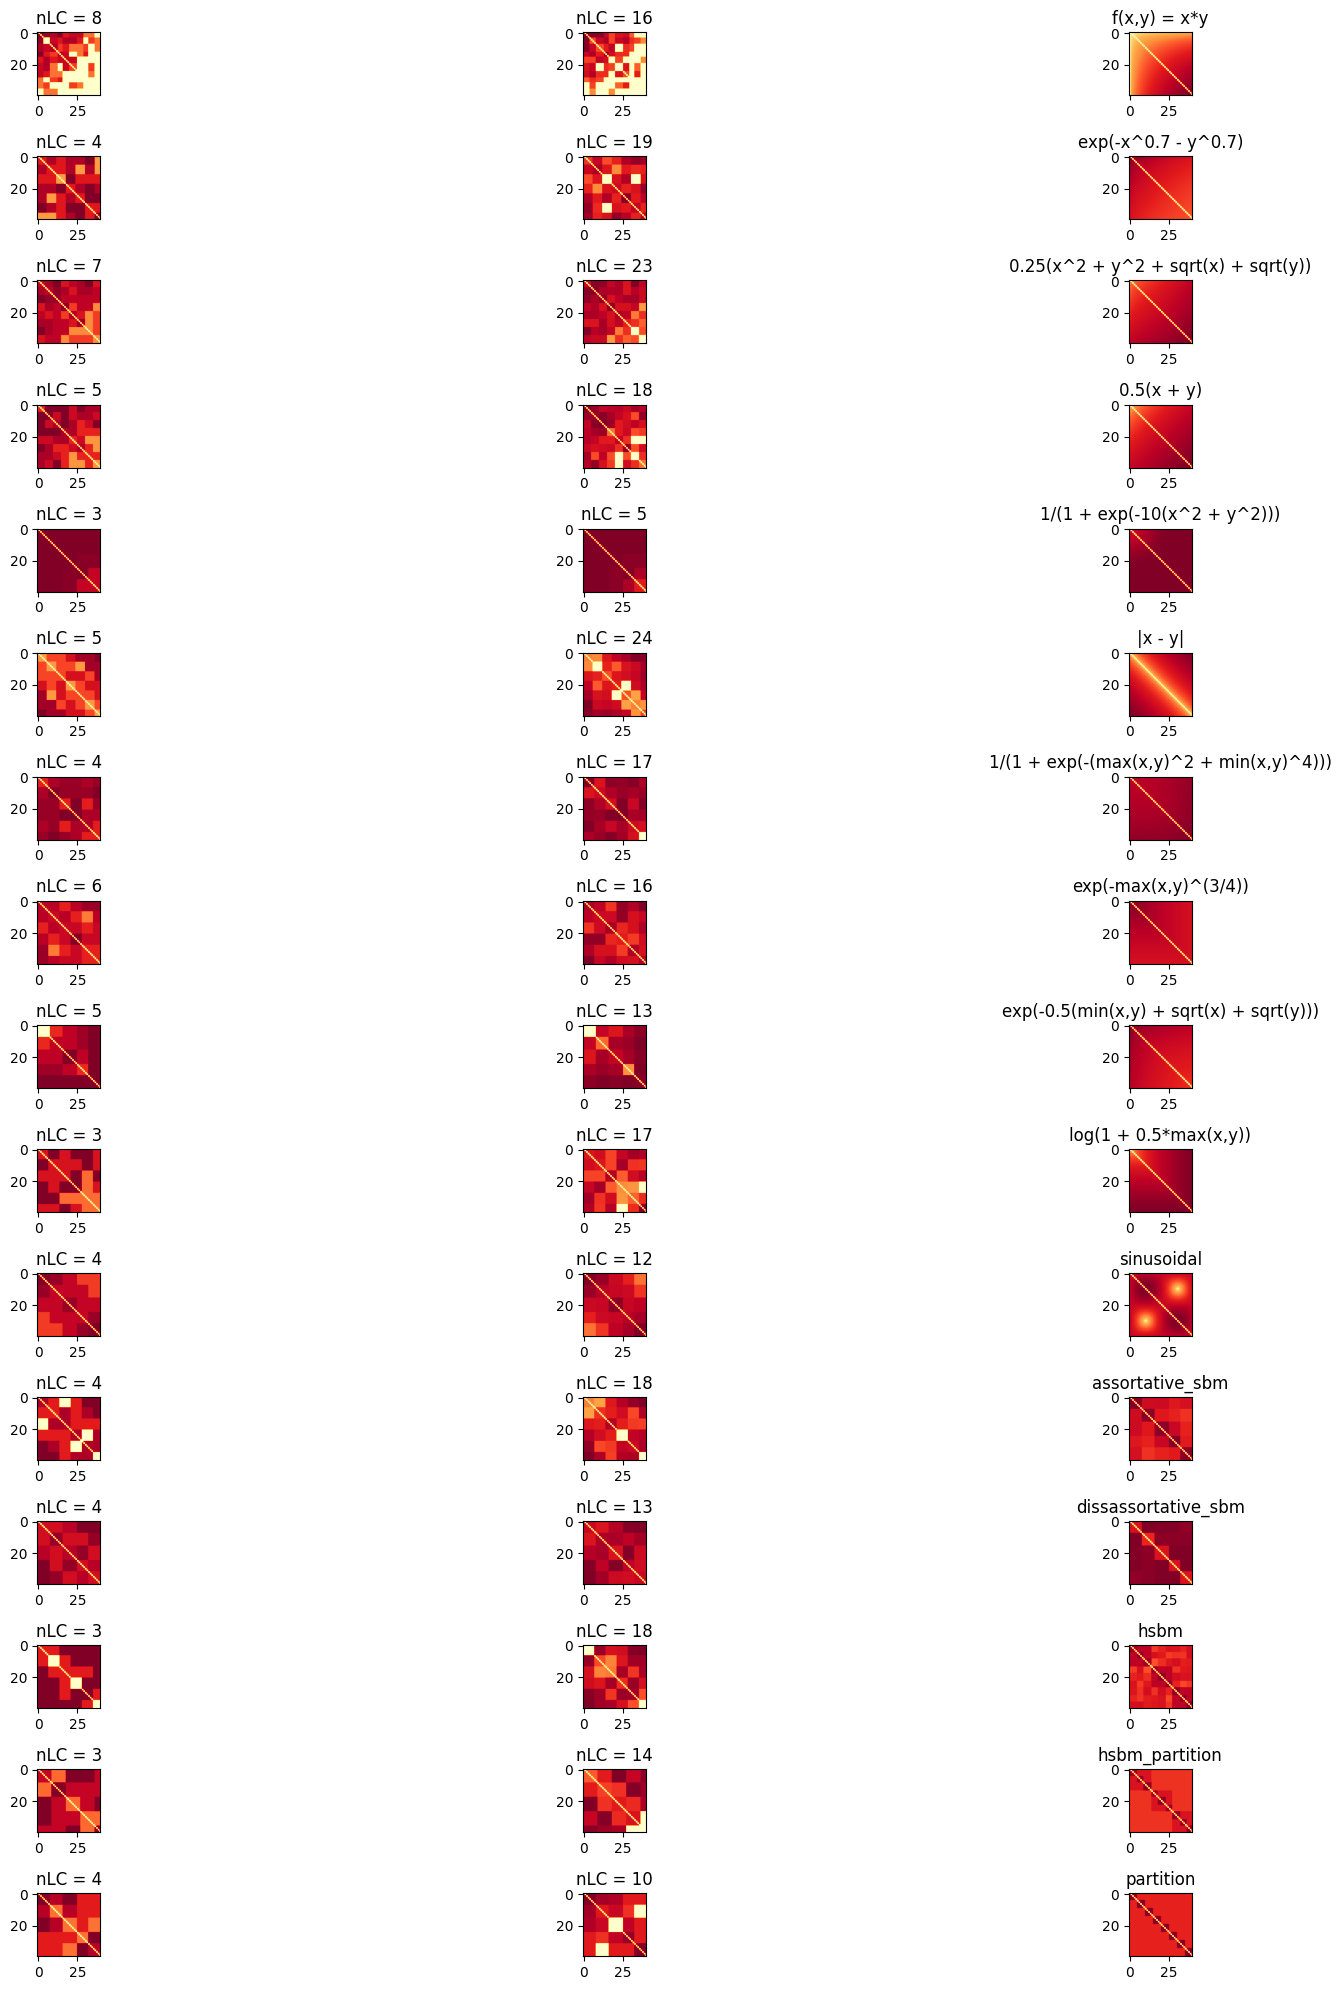

In [158]:
#Plot each graphn and its estimate in subplots iteratively
fig, axes = plt.subplots(nrows=len(common_graphons.values()), ncols=3, figsize=(20, 20))
for j,g in enumerate(common_graphons.values()):
    axes[j,0].imshow(estimators[g]["SSM"].get_edge_probabilities(n,False,True)**0.25, cmap = cmap)
    axes[j,0].set_title("nLC = " + str(len(np.unique(estimators[g]["SSM"].graphon))))
    axes[j,1].imshow(estimators[g]["Olhede"][0].get_edge_probabilities(n,False,True)**0.25, cmap = cmap)
    axes[j,1].set_title("nLC = " + str(len(np.unique(estimators[g]["Olhede"][0].graphon))))
    axes[j,2].imshow(g.get_edge_probabilities(n,False,True)**0.25, cmap = cmap)
    axes[j,2].set_title(str(g))
plt.tight_layout()
plt.show()

# HSBM, overlap, and partition model

## HSBM and partition

In [205]:
n=1000

### Regular HSBM

In [206]:
from experiments.utils_generators import generate_hierarchical_theta

# Example usage:
k = 9
m = 3
theta_min_intra = 0.7
theta_max_intra = 0.7
theta_min_meta_intra = 0.3
theta_max_meta_intra = 0.3
theta_min_inter = 0.1
theta_max_inter = 0.1


# put theta_inter's and theta_meta_intra's to equality to get partition model

theta = generate_hierarchical_theta(k, m, theta_min_intra, theta_max_intra, theta_min_meta_intra, theta_max_meta_intra, theta_min_inter, theta_max_inter)

In [193]:
import numpy as np
seed_value = 42
np.random.seed(seed_value)

graphon = StepGraphon(theta, bandwidthHist=1 /k)
adj_mat = graphon.draw(n=n, exchangeable=False)
est = SmoothNetHist(bandwidth=1/k)
est.fit(adj_mat)
estimators_SSM = est.graphon
estimators_Olhede = est._first_approximate_graphon_from_adjacency(adj_mat, bandwidthHist=1/k)

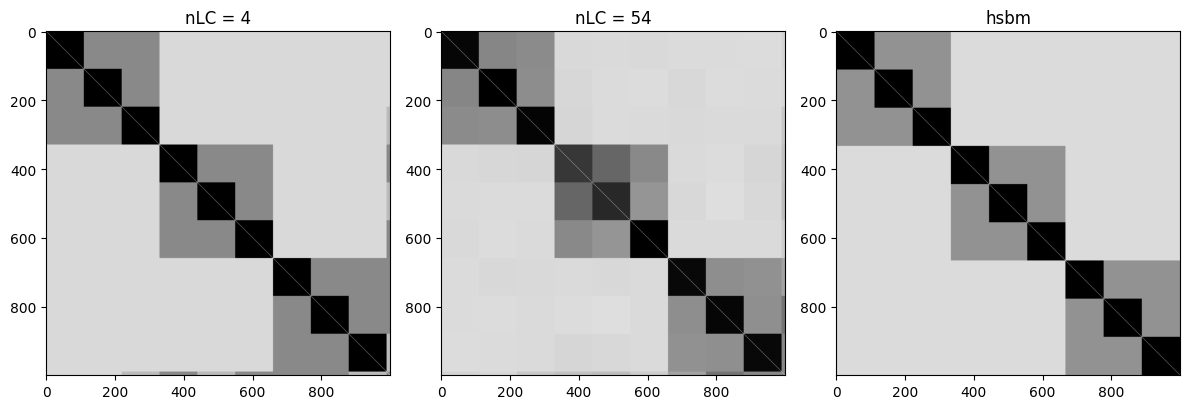

In [194]:
xticks = [0, n/ 2, n - 1]
yticks = [0, n/ 2, n - 1]

fig, axes = plt.subplots(ncols=3, figsize=(12, 20))
axes[0].imshow(estimators_SSM.get_edge_probabilities(n,False,True)/estimators_SSM.initial_rho, cmap = plt.cm.binary)
axes[0].set_title("nLC = " + str(len(np.unique(estimators_SSM.graphon))))
axes[1].imshow(estimators_Olhede[0].get_edge_probabilities(n,False,True)/estimators_Olhede[0].initial_rho, cmap = plt.cm.binary)
axes[1].set_title("nLC = " + str(len(np.unique(estimators_Olhede[0].graphon))))
axes[2].imshow(graphon.get_edge_probabilities(n,False,True)/graphon.initial_rho, cmap = plt.cm.binary)
axes[2].set_title("hsbm")
plt.tight_layout()
plt.show()

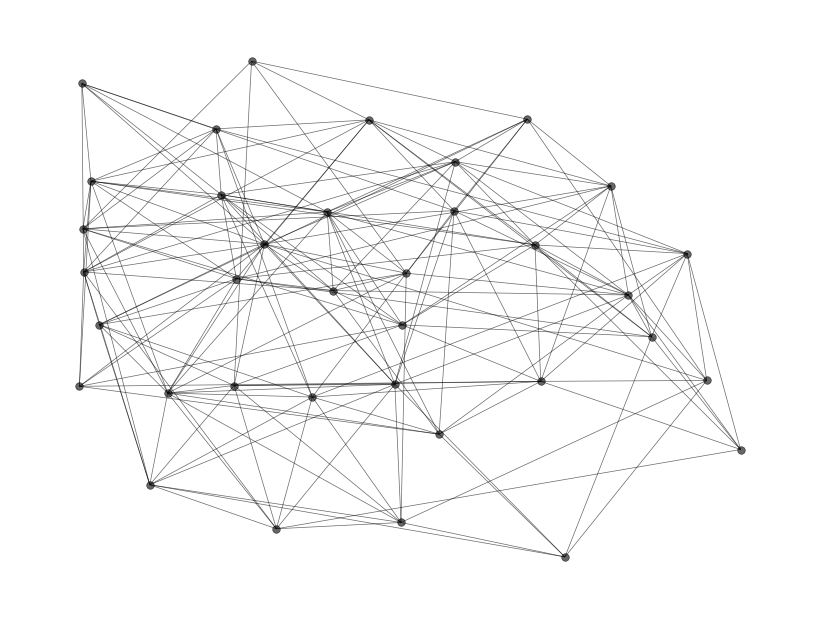

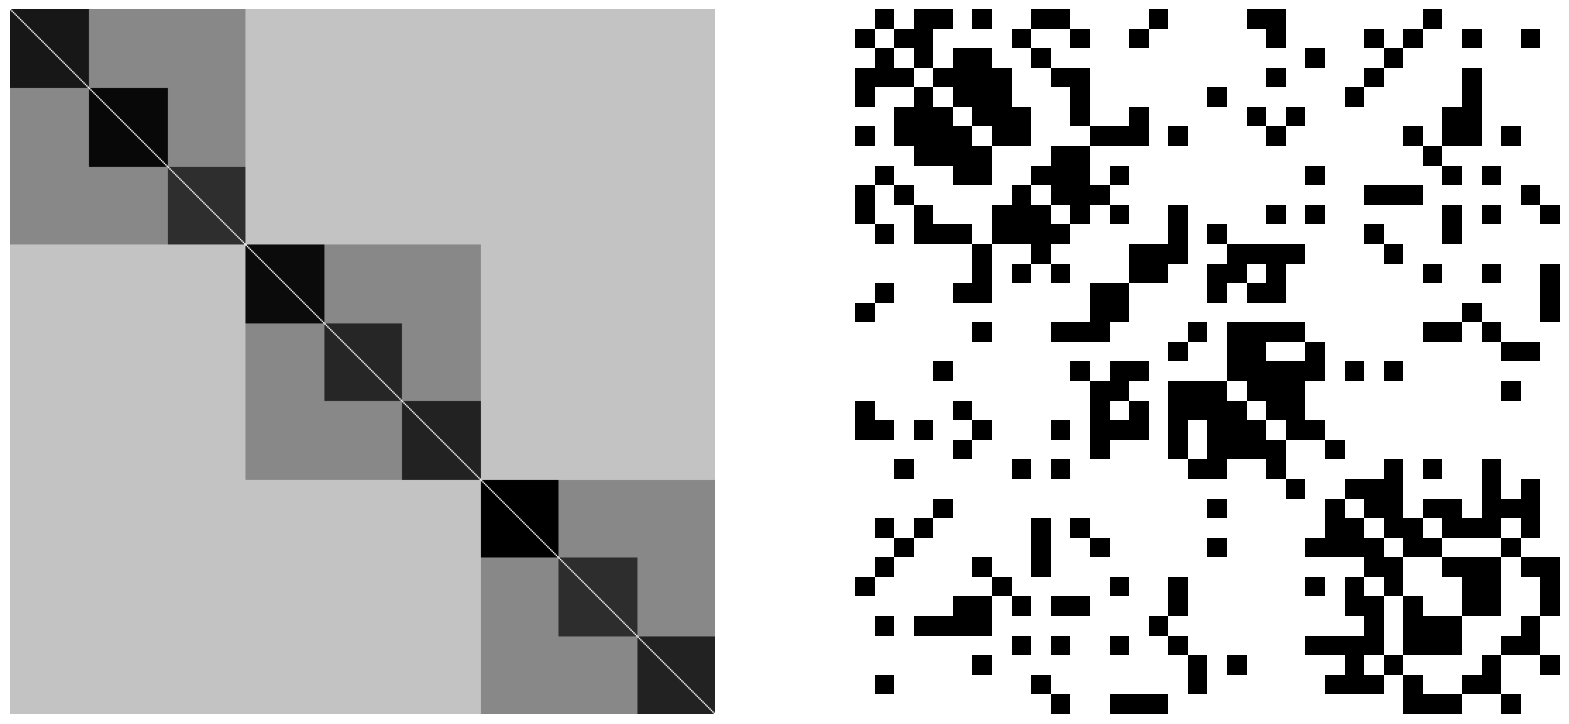

In [218]:
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
adj_mat_plot = graphon.draw(n=36, exchangeable=False)
G = nx.from_numpy_array(adj_mat_plot)
G = G.to_undirected()
G.remove_edges_from(nx.selfloop_edges(G))
#pos = nx.spring_layout(G)
pos = nx.spring_layout(G, scale=2)
plt.figure(figsize=(8, 6))
nx.draw(G, pos, edge_color='black', width=0.5, linewidths=0.5,
        node_size=30, node_color='black', alpha=0.6,)

plt.axis('off')
plt.show()

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(20, 10))

#Give black and white cmap
from pygraphon.plots.utils import make_pretty

cmap = plt.cm.binary
axes[0].imshow(graphon.get_edge_probabilities(500,False,True)/graphon.initial_rho, cmap = cmap)
make_pretty(ax=axes[0])
axes[1].imshow(adj_mat_plot, cmap = cmap)
make_pretty(ax=axes[1])

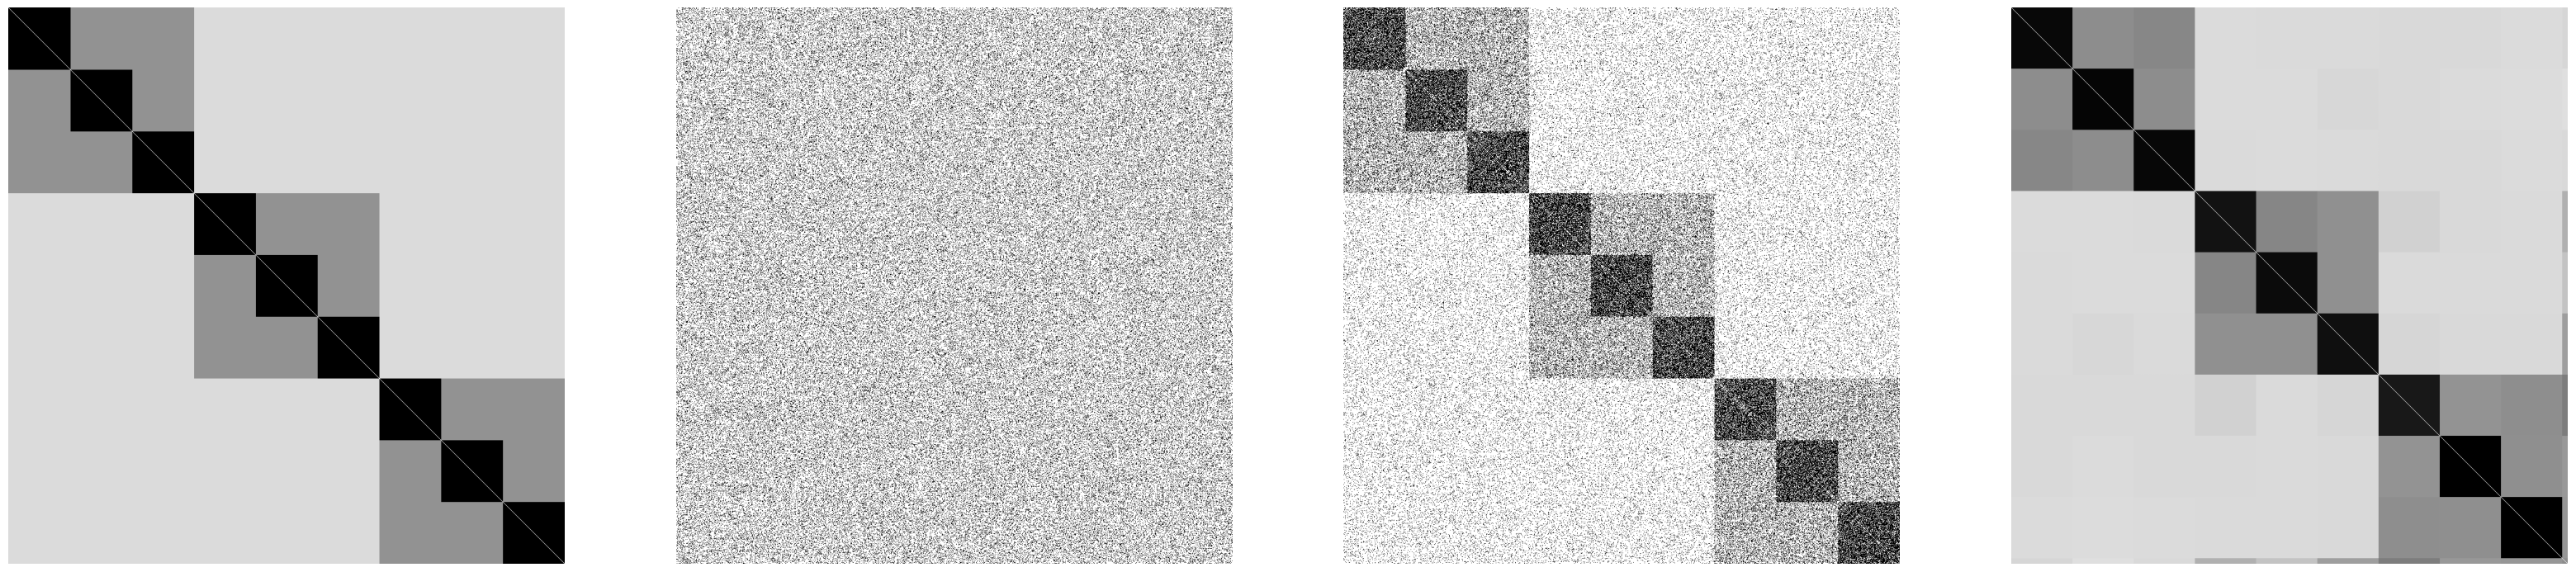

In [192]:
permuted_rows = np.random.permutation(adj_mat)

# Shuffle columns
permuted_array = np.random.permutation(permuted_rows.T).T
from pygraphon.plots.utils import make_pretty
# Plot Olhede's estimate along with adjacency matrix and randomly permuted adjacency matrix
fig, axes = plt.subplots(nrows=1, ncols=4, figsize=(40, 10))

#Give black and white cmap
cmap = plt.cm.binary
axes[0].imshow(graphon.get_edge_probabilities(n,False,True)/graphon.initial_rho, cmap = cmap)
make_pretty(ax=axes[0])
axes[1].imshow(permuted_array, cmap = cmap)
make_pretty(ax=axes[1])
axes[2].imshow(adj_mat, cmap = cmap)
make_pretty(ax=axes[2])
axes[3].imshow(estimators_Olhede[0].get_edge_probabilities(n,False,True), cmap = cmap)
make_pretty(ax=axes[3])

plt.show()

In [203]:
from experiments.utils_generators import generate_hierarchical_theta

k = 9
m = 3
theta_min_intra = 0.7
theta_max_intra = 0.9
theta_min_meta_intra = 0.4
theta_max_meta_intra = 0.4
theta_min_inter = 0.2
theta_max_inter = 0.2

theta = generate_hierarchical_theta(k, m, theta_min_intra, theta_max_intra, theta_min_meta_intra, theta_max_meta_intra, theta_min_inter, theta_max_inter)
import numpy as np
seed_value = 69
np.random.seed(seed_value)

graphon = StepGraphon(theta, bandwidthHist=1 /k)
adj_mat = graphon.draw(n=n, exchangeable=False)
est = SmoothNetHist(bandwidth=1/k)
est.fit(adj_mat)
estimators_SSM = est.graphon
estimators_Olhede = est._first_approximate_graphon_from_adjacency(adj_mat, bandwidthHist=1/k)

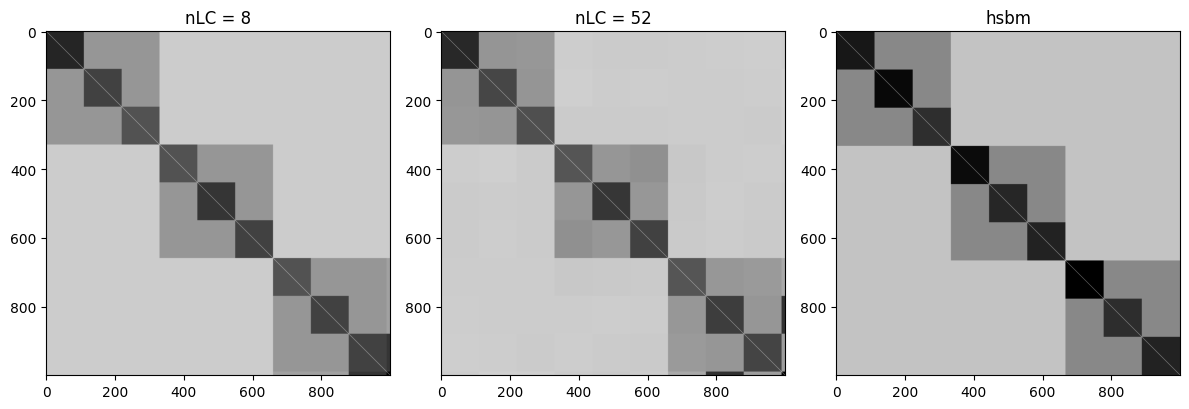

In [204]:
xticks = [0, n/ 2, n - 1]
yticks = [0, n/ 2, n - 1]

fig, axes = plt.subplots(ncols=3, figsize=(12, 20))
axes[0].imshow(estimators_SSM.get_edge_probabilities(n,False,True)/estimators_SSM.initial_rho, cmap = plt.cm.binary)
axes[0].set_title("nLC = " + str(len(np.unique(estimators_SSM.graphon))))
axes[1].imshow(estimators_Olhede[0].get_edge_probabilities(n,False,True)/estimators_Olhede[0].initial_rho, cmap = plt.cm.binary)
axes[1].set_title("nLC = " + str(len(np.unique(estimators_Olhede[0].graphon))))
axes[2].imshow(graphon.get_edge_probabilities(n,False,True)/graphon.initial_rho, cmap = plt.cm.binary)
axes[2].set_title("hsbm")
plt.tight_layout()
plt.show()

### Mix between HSBM and Partition

In [165]:
k = 15
m = 3
theta_min_intra = 0.5
theta_max_intra = 0.7
theta_min_meta_intra = 0.25
theta_max_meta_intra = 0.25
theta_min_inter = 0.15
theta_max_inter = 0.15

# put theta_inter's and theta_meta_intra's to equality to get partition model

theta = generate_hierarchical_theta(k, m, theta_min_intra, theta_max_intra, theta_min_meta_intra, theta_max_meta_intra, theta_min_inter, theta_max_inter)

In [166]:
graphon = StepGraphon(theta, bandwidthHist=1 /k)
adj_mat = graphon.draw(n=n, exchangeable=False)
est = SmoothNetHist(bandwidth=1/k)
est.fit(adj_mat)
estimators_SSM = est.graphon
estimators_Olhede = est._first_approximate_graphon_from_adjacency(adj_mat, bandwidthHist=1/k)

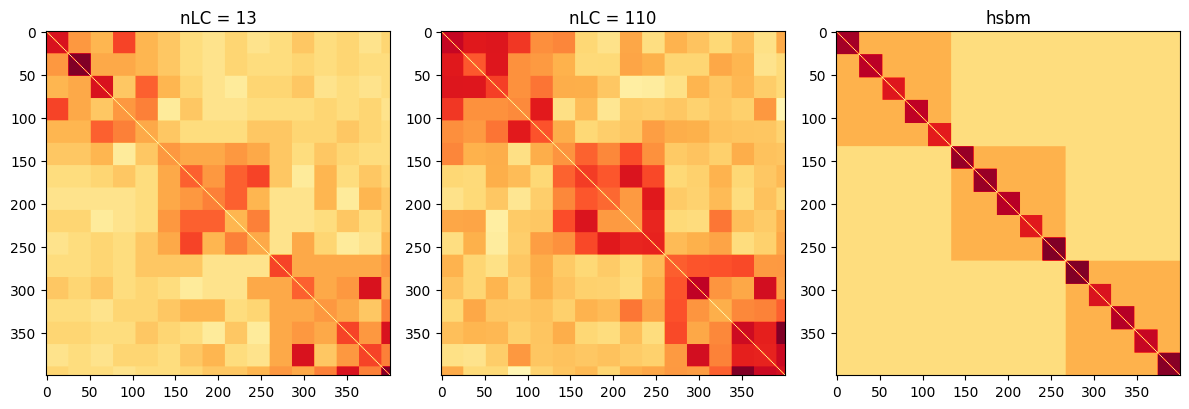

In [167]:
fig, axes = plt.subplots(ncols=3, figsize=(12, 20))
axes[0].imshow(estimators_SSM.get_edge_probabilities(n,False,True)/estimators_SSM.initial_rho, cmap = cmap)
axes[0].set_title("nLC = " + str(len(np.unique(estimators_SSM.graphon))))
axes[1].imshow(estimators_Olhede[0].get_edge_probabilities(n,False,True)/estimators_Olhede[0].initial_rho, cmap = cmap)
axes[1].set_title("nLC = " + str(len(np.unique(estimators_Olhede[0].graphon))))
axes[2].imshow(graphon.get_edge_probabilities(n,False,True)/graphon.initial_rho, cmap = cmap)
axes[2].set_title("hsbm")
plt.tight_layout()
plt.show()

### Partition model

In [168]:
k = 3
m = 1
theta_min_intra = 0.7
theta_max_intra = 0.7
theta_min_meta_intra = 0.2
theta_max_meta_intra = 0.2
theta_min_inter = 0.2
theta_max_inter = 0.2

# put m=1 to get partition model, p_ext will be defined by meta-intra-connectivity

theta = generate_hierarchical_theta(k, m, theta_min_intra, theta_max_intra, theta_min_meta_intra, theta_max_meta_intra, theta_min_inter, theta_max_inter)
print(theta)

[[0.7 0.2 0.2]
 [0.2 0.7 0.2]
 [0.2 0.2 0.7]]


In [169]:
graphon = StepGraphon(theta, bandwidthHist=1 /k)
adj_mat = graphon.draw(n=n, exchangeable=False)
est = SmoothNetHist(bandwidth=1/k)
est.fit(adj_mat)
estimators_SSM = est.graphon
estimators_Olhede = est._first_approximate_graphon_from_adjacency(adj_mat, bandwidthHist=1/k)

In [170]:
print(est.graphon)
print(estimators_Olhede[0])

StepGraphon 
[[0.704 0.198 0.198 0.350]
 [0.198 0.704 0.198 0.350]
 [0.198 0.198 0.704 0.350]
 [0.350 0.350 0.350 0.350]]

 [0.109 0.109 0.109 0.003] (size of the blocks)
StepGraphon 
[[0.710 0.198 0.197 0.288]
 [0.198 0.700 0.200 0.354]
 [0.197 0.200 0.700 0.422]
 [0.288 0.354 0.422 0.167]]

 [0.109 0.109 0.109 0.003] (size of the blocks)


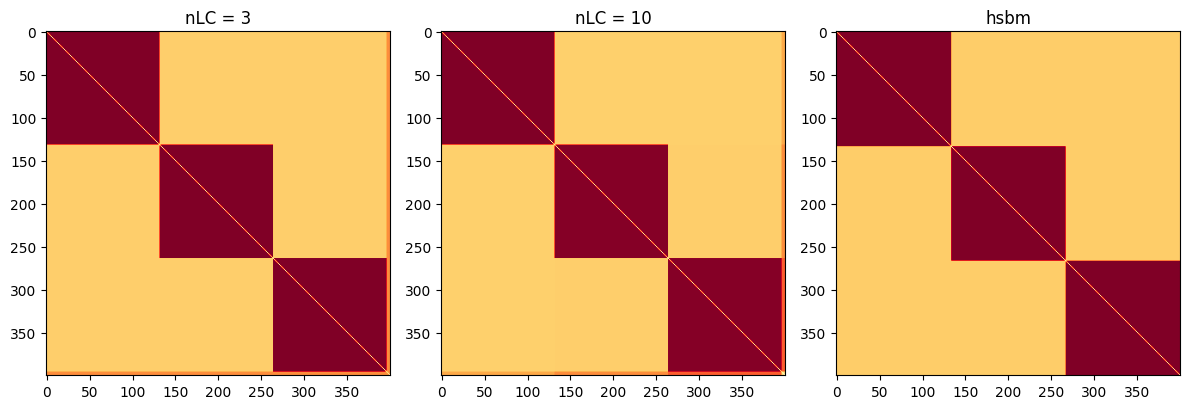

In [171]:
fig, axes = plt.subplots(ncols=3, figsize=(12, 20))
axes[0].imshow(estimators_SSM.get_edge_probabilities(n,False,True)/estimators_SSM.initial_rho, cmap = cmap)
axes[0].set_title("nLC = " + str(len(np.unique(estimators_SSM.graphon))))
axes[1].imshow(estimators_Olhede[0].get_edge_probabilities(n,False,True)/estimators_Olhede[0].initial_rho, cmap = cmap)
axes[1].set_title("nLC = " + str(len(np.unique(estimators_Olhede[0].graphon))))
axes[2].imshow(graphon.get_edge_probabilities(n,False,True)/graphon.initial_rho, cmap = cmap)
axes[2].set_title("hsbm")
plt.tight_layout()
plt.show()

## OSBM

In [172]:
import numpy as np

def generate_osbm_theta(k, shared_inter_sets, theta_min_intra, theta_max_intra, theta_min_inter, theta_max_inter):
    """
    Generate a symmetric connectivity matrix θ for an OSBM with specific inter-connectivity behavior.

    Parameters:
    - k: total number of blocks (should be at least 3)
    - shared_inter_sets: number of sets of blocks with shared inter-connectivity values
    - theta_min_intra, theta_max_intra: intra-connectivity range within a block
    - theta_min_inter, theta_max_inter: inter-connectivity range between blocks

    Returns:
    - θ: k x k symmetric connectivity matrix for OSBM
    """
    
    if k < 3:
        raise ValueError("The number of blocks k should be at least 3.")

    theta = np.zeros((k, k))
    shared_sets = [np.random.choice(k, 3, replace=False) for _ in range(shared_inter_sets)]

    for i in range(k):
        for j in range(i, k):  # Only loop over the upper triangle including the diagonal
            
            shared_value = None
            for shared_set in shared_sets:
                if i in shared_set and j in shared_set and i != j:
                    if shared_value is None:
                        shared_value = np.random.uniform(theta_min_inter, theta_max_inter)
                    theta[i, j] = shared_value
                    break

            if i == j:
                theta[i, j] = np.random.uniform(theta_min_intra, theta_max_intra)
            elif theta[i, j] == 0:
                theta[i, j] = np.random.uniform(theta_min_inter, theta_max_inter)
            
            # Make the matrix symmetric
            theta[j, i] = theta[i, j]

    return theta

# Example usage:
k = 5
shared_inter_sets = 2
theta_min_intra = 0.7
theta_max_intra = 1.0
theta_min_inter = 0.1
theta_max_inter = 0.3

theta = generate_osbm_theta(k, shared_inter_sets, theta_min_intra, theta_max_intra, theta_min_inter, theta_max_inter)
print(theta)


[[0.7927611  0.23397412 0.10709607 0.17997671 0.2030487 ]
 [0.23397412 0.87802148 0.19654645 0.29509518 0.29620927]
 [0.10709607 0.19654645 0.82656884 0.24968063 0.20177335]
 [0.17997671 0.29509518 0.24968063 0.87923899 0.25169461]
 [0.2030487  0.29620927 0.20177335 0.25169461 0.8906246 ]]


# SSM